# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Cut Jazlin Amina
- **Email:** cutjazlinamina05@gmail.com
- **ID Dicoding:** ds322b6x0392

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Pada jam berapa penyewaan sepeda mencapai puncak di hari kerja dibandingkan hari libur/akhir pekan sepanjang 2011-2012, dan berapa rata-rata penyewaan per jam pada jam puncak tersebut? Hasilnya dipakai untuk mengatur jadwal redistribusi sepeda antar stasiun.
- **Pertanyaan 2:** Seberapa besar penurunan rata-rata penyewaan harian pada tiap musim dan kondisi cuaca dibandingkan kondisi terbaiknya (musim dengan rata-rata tertinggi dan cuaca cerah) sepanjang 2011-2012? Hasilnya dipakai untuk menentukan waktu promosi dan jadwal perawatan armada.
- **Pertanyaan 3:** Berapa persen pertumbuhan total penyewaan pada setiap bulan di 2012 dibandingkan bulan yang sama di 2011, dan bulan apa yang pertumbuhannya paling tinggi dan paling rendah? Hasilnya dipakai untuk menyusun target penyewaan dan kapasitas armada per bulan.
- **Pertanyaan 4:** Berapa persen pengguna casual terhadap total penyewaan pada hari kerja dibandingkan hari libur/akhir pekan, dan pada tiap musim, sepanjang 2011-2012? Hasilnya dipakai untuk menentukan waktu dan segmen promosi agar pengguna casual berpindah menjadi anggota terdaftar.

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load day_df

In [2]:
# Membuat data day

day_df = pd.read_csv("data/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- Hasil head dari load day_df menampilkan 5 baris pertama data dengan 16 kolom yaitu instant, dteday, season, yr, mnth, holiday, weekday, workingday, weathersit, temp, atemp, hum, windspeed, casual, registered, dan cnt.
- Kolom cnt merupakan jumlahan total sepeda yang disewa oleh casual users (casual) dan registered users (registered)

#### Load hour_df

In [3]:
# Membuat data hour

hour_df = pd.read_csv("data/hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Hasil head dari load hour_df menampilkan 5 baris pertama data dari 17 kolom yaitu instant, dteday, season, yr, mnth, hr, holiday, weekday, workingday, weathersit, temp, atemp, hum, windspeed, casual, registered, dan cnt.
- Kolom kategorik seperti season, weathersit, dan weekday masih berupa kode angka, sedangkan temp, atemp, hum, dan windspeed masih dalam bentuk ternormalisasi.
- Sama seperti day_df, Kolom cnt di sini juga merupakan jumlahan total sepeda yang disewa oleh casual users (casual) dan registered users (registered)

### Assessing Data

#### Identifying day_df problem

In [4]:
# Menampilkan informasi tentang data day

day_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB


In [5]:
# Menampilkan jumlah nilai yang hilang pada setiap kolom di data day

day_df.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [6]:
# Menampilkan jumlah duplikasi pada data day

print("Jumlah duplikasi:", day_df.duplicated().sum())

Jumlah duplikasi: 0


In [7]:

# Menampilkan ringkasan statistik dari data day

day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [8]:
# Menampilkan hari dengan kelembapan = 0

print("Hari dengan kelembapan = 0")
print(day_df[day_df['hum'] == 0])

Hari dengan kelembapan = 0
    instant      dteday  season  yr  mnth  holiday  weekday  workingday  \
68       69  2011-03-10       1   0     3        0        4           1   

    weathersit      temp     atemp  hum  windspeed  casual  registered  cnt  
68           3  0.389091  0.385668  0.0   0.261877      46         577  623  


**Steps to Take:**
- Mengubah tipe data kolom dteday menjadi datetime
- Mengubah nama kolom:
    - dteday → dateday
    - yr → year
    - mnth → month
    - workingday → day_type
    - weathersit → weather_cond
    - cnt → count
    - hum → humidity
    - temp → temperature
    - atemp → feeling_temperature
- Mengganti kode angka pada season, yr, holiday, workingday, weathersit, dan weekday dengan label yang bermakna.
- Mengonversi kolom temperature, feeling_temperature, humidity, dan windspeed ke nilai aslinya (dikali 41, 50, 100, dan 67).
- Mengisi nilai hum = 0 pada day_df (10 Maret 2011) dengan rerata kelembapan pada hari yang sama dari hour_df yang sudah diimputasi.

**Insight:**
- Tidak ada missing value maupun data duplikat pada day_df.
- Masalah yang ditemukan: tipe data dteday yang salah, terdapat nilai kelembapan 0 yang tidak valid pada 10 Maret 2011, dan terdapat kolom yang masih ternormalisasi.
- Nama-nama kolom seperti dteday, yr, mnth, workingday, weathersit, atemp, dan cnt tidak mudah dibaca dan tidak dapat langsung dipahami maknanya.
- Kolom season, yr, holiday, workingday, weathersit, dan weekday masih berupa kode angka sehingga kurang informatif untuk dianalisis dan divisualisasikan.

#### Identifying hour_df problem

In [9]:
# Menampilkan informasi tentang data hour

hour_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.4 MB


In [10]:
# Menampilkan jumlah nilai yang hilang pada setiap kolom di data hour

hour_df.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [11]:
# Menampilkan jumlah duplikasi pada data hour

print("Jumlah duplikasi:", hour_df.duplicated().sum())

Jumlah duplikasi: 0


In [12]:
# Menampilkan ringkasan statistik dari data hour

hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [13]:
# Menampilkan jumlah jam dengan kelembapan = 0 dan tanggalnya

print("Jumlah jam dengan kelembapan = 0:", (hour_df["hum"] == 0).sum())
print("Tanggal-nya:", hour_df.loc[hour_df["hum"] == 0, "dteday"].unique())

Jumlah jam dengan kelembapan = 0: 22
Tanggal-nya: <ArrowStringArray>
['2011-03-10']
Length: 1, dtype: str


**Steps to Take:**
- Mengubah tipe data kolom dteday menjadi datetime
- Mengubah nama kolom:
    - dteday → dateday
    - yr → year
    - mnth → month
    - hr → hour
    - workingday → day_type
    - weathersit → weather_cond
    - cnt → count
    - hum → humidity
    - temp → temperature
    - atemp → feeling_temperature
- Mengganti kode angka pada season, yr, holiday, workingday, weathersit, dan weekday dengan label yang bermakna.
- Mengonversi kolom temperature, feeling_temperature, humidity, dan windspeed ke nilai aslinya (dikali 41, 50, 100, dan 67).
- Mengganti nilai hum = 0 pada 10 Maret 2011 dengan median kelembapan pada jam yang sama di bulan Maret 2011 (dihitung tanpa nilai 0), agar pola harian kelembapan tetap terjaga.

**Insight:**
- Tidak ada missing value maupun data duplikat pada hour_df.
- Masalah yang ditemukan: tipe data dteday yang salah, ditemukan 22 baris dengan nilai kelembapan 0 yang tidak valid yaitu pada 10 Maret 2011, dan terdapat kolom yang masih ternormalisasi.
- Nama-nama kolom seperti dteday, yr, mnth, hr, workingday, weathersit, atemp, dan cnt tidak mudah dibaca dan tidak dapat langsung dipahami maknanya.
- Kolom season, yr, holiday, workingday, weathersit, dan weekday masih berupa kode angka sehingga kurang informatif untuk dianalisis dan divisualisasikan.

### Cleaning Data

hour_df dibersihkan lebih dulu karena nilai kelembapan pada day_df diisi dari rerata kelembapan hour_df yang sudah diimputasi. Hasil pembersihan disimpan ke folder dashboard sebagai data utama dashboard.

#### Fixing hour_df problem

In [14]:
# Mengubah tipe data dteday menjadi datetime

hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

In [15]:
# Mengubah nama kolom menjadi lebih deskriptif

hour_df.rename(columns={
    'dteday': 'dateday',
    'yr': 'year',
    'mnth': 'month',
    'hr': 'hour',
    'workingday': 'day_type',
    'weathersit': 'weather_cond',
    'cnt': 'count',
    'hum': 'humidity',
    'temp': 'temperature',
    'atemp': 'feeling_temperature'
}, inplace=True)

In [16]:
# Mengganti kode angka dengan label yang lebih deskriptif

hour_df['season'] = hour_df['season'].map({1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'})
hour_df['year'] = hour_df['year'].map({0: 2011, 1: 2012})
hour_df['holiday'] = hour_df['holiday'].map({1: 'Holiday', 0: 'Not Holiday'})
hour_df['day_type'] = hour_df['day_type'].map({1: 'Workday', 0: 'Weekend/Holiday'})
hour_df['weather_cond'] = hour_df['weather_cond'].map({
    1: 'Clear',
    2: 'Misty',
    3: 'Light Rain/Snow',
    4: 'Heavy Rain/Snow'
})
hour_df['weekday'] = hour_df['weekday'].map({
    0: 'Sun', 1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat'
})

In [17]:
# Mengonversi kolom ternormalisasi ke nilai aslinya

scale_factors = {'temperature': 41, 'feeling_temperature': 50, 'humidity': 100, 'windspeed': 67}

for column, factor in scale_factors.items():
    hour_df[column] = (hour_df[column] * factor).round(2)

In [18]:
# Mengimputasi nilai kelembapan yang tidak valid (0) pada data hour dengan median kelembapan per jam di bulan Maret 2011 (tanpa nilai 0)

march_2011 = (hour_df['dateday'].dt.year == 2011) & (hour_df['dateday'].dt.month == 3)
valid_march_2011 = march_2011 & (hour_df['humidity'] > 0)
median_humidity_per_hour = hour_df[valid_march_2011].groupby('hour')['humidity'].median()

invalid_humidity = hour_df['humidity'] == 0
hour_df.loc[invalid_humidity, 'humidity'] = hour_df.loc[invalid_humidity, 'hour'].map(median_humidity_per_hour)

In [19]:
# Mengecek informasi data hour setelah pembersihan

hour_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   instant              17379 non-null  int64         
 1   dateday              17379 non-null  datetime64[us]
 2   season               17379 non-null  str           
 3   year                 17379 non-null  int64         
 4   month                17379 non-null  int64         
 5   hour                 17379 non-null  int64         
 6   holiday              17379 non-null  str           
 7   weekday              17379 non-null  str           
 8   day_type             17379 non-null  str           
 9   weather_cond         17379 non-null  str           
 10  temperature          17379 non-null  float64       
 11  feeling_temperature  17379 non-null  float64       
 12  humidity             17379 non-null  float64       
 13  windspeed            17379 non-null  float

In [20]:
# Mengecek jumlah jam dengan kelembapan = 0 setelah imputasi

print((hour_df['humidity'] == 0).sum())

0


In [21]:
# Menampilkan kelembapan pada 10 Maret 2011 setelah imputasi

hour_df.loc[hour_df['dateday'] == '2011-03-10', ['dateday', 'hour', 'humidity']].head()

,dateday,hour,humidity
1551,2011-03-10,0,63.5
1552,2011-03-10,1,65.5
1553,2011-03-10,2,65.0
1554,2011-03-10,5,72.0
1555,2011-03-10,6,74.5


**Insight:**
- Setelah dibersihkan, semua kolom sudah bertipe sesuai, kolom kategorik terbaca langsung tanpa membuka Readme, dan kolom cuaca sudah dalam satuan aslinya (suhu dalam °C dan kelembapan dalam %).
- Kelembapan pada setiap jam di 10 Maret 2011 sekarang sudah terisi dengan median kelembapan per jam di bulan Maret 2011 (tanpa nilai 0).

In [22]:
# Menyimpan data hour yang sudah dibersihkan untuk dashboard

os.makedirs("dashboard", exist_ok=True)
hour_df.to_csv("dashboard/main_data_hour.csv", index=False)

#### Fixing day_df problem

In [23]:
# Mengubah tipe data dteday menjadi datetime

day_df['dteday'] = pd.to_datetime(day_df['dteday'])

In [24]:
# Mengubah nama kolom menjadi lebih deskriptif

day_df.rename(columns={
    'dteday': 'dateday',
    'yr': 'year',
    'mnth': 'month',
    'workingday': 'day_type',
    'weathersit': 'weather_cond',
    'cnt': 'count',
    'hum': 'humidity',
    'temp': 'temperature',
    'atemp': 'feeling_temperature'
}, inplace=True)

In [25]:
# Mengganti kode angka dengan label yang lebih deskriptif

day_df['season'] = day_df['season'].map({1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'})
day_df['year'] = day_df['year'].map({0: 2011, 1: 2012})
day_df['holiday'] = day_df['holiday'].map({1: 'Holiday', 0: 'Not Holiday'})
day_df['day_type'] = day_df['day_type'].map({1: 'Workday', 0: 'Weekend/Holiday'})
day_df['weather_cond'] = day_df['weather_cond'].map({
    1: 'Clear',
    2: 'Misty',
    3: 'Light Rain/Snow',
    4: 'Heavy Rain/Snow'
})
day_df['weekday'] = day_df['weekday'].map({
    0: 'Sun', 1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat'
})

In [26]:
# Mengonversi kolom ternormalisasi ke nilai aslinya

for column, factor in scale_factors.items():
    day_df[column] = (day_df[column] * factor).round(2)

In [27]:
# Mengisi nilai kelembapan yang tidak valid (0) pada data day dengan rerata kelembapan hari itu dari data hour yang sudah diimputasi

mean_humidity = hour_df.loc[hour_df['dateday'] == '2011-03-10', 'humidity'].mean().round(2)
day_df.loc[day_df['dateday'] == '2011-03-10', 'humidity'] = mean_humidity

In [28]:
# Mengecek informasi data day setelah pembersihan

day_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   instant              731 non-null    int64         
 1   dateday              731 non-null    datetime64[us]
 2   season               731 non-null    str           
 3   year                 731 non-null    int64         
 4   month                731 non-null    int64         
 5   holiday              731 non-null    str           
 6   weekday              731 non-null    str           
 7   day_type             731 non-null    str           
 8   weather_cond         731 non-null    str           
 9   temperature          731 non-null    float64       
 10  feeling_temperature  731 non-null    float64       
 11  humidity             731 non-null    float64       
 12  windspeed            731 non-null    float64       
 13  casual               731 non-null    int64    

In [29]:
# Mengecek jumlah hari dengan kelembapan = 0 setelah imputasi

print((day_df['humidity'] == 0).sum())

0


In [30]:
# Menampilkan kelembapan pada 10 Maret 2011 setelah imputasi

day_df.loc[day_df['dateday'] == '2011-03-10', ['dateday', 'humidity']]

,dateday,humidity
68,2011-03-10,55.0


**Insight:**
- Setelah dibersihkan, semua kolom sudah bertipe sesuai, kolom kategorik terbaca langsung tanpa membuka Readme, dan kolom cuaca sudah dalam satuan aslinya (suhu dalam °C dan kelembapan dalam %).
- Kelembapan pada 10 Maret 2011 sekarang sudah terisi dengan rerata kelembapan hari itu dari hour_df yang sudah diimputasi dengan median per jam di bulan Maret 2011, sehingga konsisten dengan hour_df.

In [31]:
# Menyimpan data day yang sudah dibersihkan untuk dashboard

day_df.to_csv("dashboard/main_data.csv", index=False)

## Exploratory Data Analysis (EDA)

### Explore day_df

In [32]:
# Menampilkan ringkasan statistik dari seluruh kolom pada data day

day_df.describe(include='all')

,instant,dateday,season,year,month,holiday,weekday,day_type,weather_cond,temperature,feeling_temperature,humidity,windspeed,casual,registered,count
count,731.000000,731,731,731.000000,731.000000,731,731,731,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
unique,NaN,NaN,4,NaN,NaN,2,7,2,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,Fall,NaN,NaN,Not Holiday,Sat,Workday,Clear,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,188,NaN,NaN,710,105,500,463,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,366.000000,2012-01-01 00:00:00,NaN,2011.500684,6.519836,NaN,NaN,NaN,NaN,20.310821,23.717784,62.864596,12.762654,848.176471,3656.172367,4504.348837
min,1.000000,2011-01-01 00:00:00,NaN,2011.000000,1.000000,NaN,NaN,NaN,NaN,2.420000,3.950000,18.790000,1.500000,2.000000,20.000000,22.000000
25%,183.500000,2011-07-02 12:00:00,NaN,2011.000000,4.000000,NaN,NaN,NaN,NaN,13.820000,16.895000,52.105000,9.040000,315.500000,2497.000000,3152.000000
50%,366.000000,2012-01-01 00:00:00,NaN,2012.000000,7.000000,NaN,NaN,NaN,NaN,20.430000,24.340000,62.670000,12.130000,713.000000,3662.000000,4548.000000
75%,548.500000,2012-07-01 12:00:00,NaN,2012.000000,10.000000,NaN,NaN,NaN,NaN,26.875000,30.430000,73.020000,15.625000,1096.000000,4776.500000,5956.000000
max,731.000000,2012-12-31 00:00:00,NaN,2012.000000,12.000000,NaN,NaN,NaN,NaN,35.330000,42.040000,97.250000,34.000000,3410.000000,6946.000000,8714.000000


In [33]:
# Menentukan urutan musim dan kondisi cuaca yang dipakai pada analisis

season_order = ['Spring', 'Summer', 'Fall', 'Winter']
weather_order = ['Clear', 'Misty', 'Light Rain/Snow']

In [34]:
# Menghitung total sewa dan rata-rata sewa harian berdasarkan tahun

yearly_rentals = day_df.groupby('year').agg(
    total_rentals=('count', 'sum'),
    avg_daily_rentals=('count', 'mean')
).round(1)
yearly_rentals

,total_rentals,avg_daily_rentals
year,,
2011,1243103,3405.8
2012,2049576,5599.9


In [35]:
# Menghitung rata-rata sewa harian, median, dan jumlah hari per musim beserta selisihnya terhadap musim tertinggi

season_stats = day_df.groupby('season').agg(
    avg_rentals=('count', 'mean'),
    median_rentals=('count', 'median'),
    days=('count', 'count')
)
season_stats['gap_vs_best_pct'] = (season_stats['avg_rentals'] / season_stats['avg_rentals'].max() - 1) * 100
season_stats.sort_values('avg_rentals', ascending=False).round(1)

,avg_rentals,median_rentals,days,gap_vs_best_pct
season,,,,
Fall,5644.3,5353.5,188,0.0
Summer,4992.3,4941.5,184,-11.6
Winter,4728.2,4634.5,178,-16.2
Spring,2604.1,2209.0,181,-53.9


In [36]:
# Menghitung rata-rata sewa harian, median, dan jumlah hari per kondisi cuaca beserta selisihnya terhadap cuaca cerah

weather_stats = day_df.groupby('weather_cond').agg(
    avg_rentals=('count', 'mean'),
    median_rentals=('count', 'median'),
    days=('count', 'count')
)
weather_stats['gap_vs_clear_pct'] = (weather_stats['avg_rentals'] / weather_stats.loc['Clear', 'avg_rentals'] - 1) * 100
weather_stats.sort_values('avg_rentals', ascending=False).round(1)

,avg_rentals,median_rentals,days,gap_vs_clear_pct
weather_cond,,,,
Clear,4876.8,4844.0,463,0.0
Misty,4035.9,4040.0,247,-17.2
Light Rain/Snow,1803.3,1817.0,21,-63.0


In [37]:
# Menghitung rata-rata sewa harian pada setiap kombinasi musim dan kondisi cuaca

season_weather_avg = day_df.groupby(['season', 'weather_cond'])['count'].mean().unstack()
season_weather_avg = season_weather_avg.reindex(index=season_order, columns=weather_order).round(0)
season_weather_avg

weather_cond,Clear,Misty,Light Rain/Snow
season,,,
Spring,2811.0,2357.0,935.0
Summer,5549.0,4237.0,1169.0
Fall,5878.0,5222.0,2752.0
Winter,5044.0,4654.0,1962.0


In [38]:
# Menghitung korelasi antara jumlah sewa dengan variabel cuaca

day_df[['count', 'temperature', 'feeling_temperature', 'humidity', 'windspeed']].corr()['count'].round(2)

count                  1.00
temperature            0.63
feeling_temperature    0.63
humidity              -0.11
windspeed             -0.23
Name: count, dtype: float64

In [39]:
# Menghitung total sewa per bulan pada 2011 dan 2012 beserta persentase pertumbuhannya

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_rentals = day_df.groupby(['month', 'year'])['count'].sum().unstack()
monthly_rentals['growth_pct'] = ((monthly_rentals[2012] / monthly_rentals[2011] - 1) * 100).round(1)
monthly_rentals.index = month_names
monthly_rentals

year,2011,2012,growth_pct
Jan,38189,96744,153.3
Feb,48215,103137,113.9
Mar,64045,164875,157.4
Apr,94870,174224,83.6
May,135821,195865,44.2
Jun,143512,202830,41.3
Jul,141341,203607,44.1
Aug,136691,214503,56.9
Sep,127418,218573,71.5
Oct,123511,198841,61.0


In [40]:
# Menampilkan bulan dengan pertumbuhan tertinggi dan terendah

print("Highest growth:", monthly_rentals['growth_pct'].idxmax(), monthly_rentals['growth_pct'].max())
print("Lowest growth:", monthly_rentals['growth_pct'].idxmin(), monthly_rentals['growth_pct'].min())

Highest growth: Mar 157.4
Lowest growth: Jun 41.3


In [41]:
# Menghitung persentase pengguna casual berdasarkan tipe hari

casual_share_day_type = day_df.groupby('day_type')[['casual', 'registered', 'count']].sum()
casual_share_day_type['casual_pct'] = (casual_share_day_type['casual'] / casual_share_day_type['count'] * 100).round(1)
casual_share_day_type

,casual,registered,count,casual_pct
day_type,,,,
Weekend/Holiday,316732,683537,1000269,31.7
Workday,303285,1989125,2292410,13.2


In [42]:
# Menghitung persentase pengguna casual berdasarkan musim

casual_share_season = day_df.groupby('season')[['casual', 'registered', 'count']].sum()
casual_share_season['casual_pct'] = (casual_share_season['casual'] / casual_share_season['count'] * 100).round(1)
casual_share_season.sort_values('casual_pct', ascending=False)

,casual,registered,count,casual_pct
season,,,,
Summer,203522,715067,918589,22.2
Fall,226091,835038,1061129,21.3
Winter,129782,711831,841613,15.4
Spring,60622,410726,471348,12.9


In [43]:
# Menghitung persentase pengguna casual pada setiap kombinasi musim dan tipe hari

casual_share_combined = day_df.groupby(['season', 'day_type'])[['casual', 'count']].sum()
casual_share_combined['casual_pct'] = (casual_share_combined['casual'] / casual_share_combined['count'] * 100).round(1)
casual_share_combined = casual_share_combined['casual_pct'].unstack().reindex(season_order)
casual_share_combined

day_type,Weekend/Holiday,Workday
season,,
Spring,23.5,8.5
Summer,36.7,15.5
Fall,34.4,15.9
Winter,27.2,10.1


**Insight:**
- Total penyewaan naik dari 1.243.103 pada 2011 menjadi 2.049.576 pada 2012, dan rata-rata harian naik dari sekitar 3.406 menjadi 5.600 sewa (naik sekitar 64%).
- Rata-rata penyewaan harian tertinggi ada di musim Fall (5.644). Musim Summer 11,6% lebih rendah, Winter 16,2% lebih rendah, dan Spring paling rendah dengan selisih 53,9%.
- Dibandingkan cuaca Clear (4.877 sewa per hari), cuaca Misty turun 17,2% dan Light Rain/Snow turun 63,0%. Cuaca Light Rain/Snow hanya terjadi pada 21 hari, dan tidak ada hari dengan cuaca Heavy Rain/Snow pada day_df.
- Pada setiap musim, rata-rata sewa selalu paling tinggi saat cuaca Clear dan paling rendah saat Light Rain/Snow.
- Suhu berkorelasi positif sedang dengan jumlah sewa (0,63), sedangkan kelembapan (-0,11) dan kecepatan angin (-0,23) berkorelasi negatif lemah.
- Seluruh bulan pada 2012 lebih tinggi daripada bulan yang sama pada 2011. Pertumbuhan tertinggi terjadi pada Maret (157,4%) dan terendah pada Juni (41,3%).
- Pengguna casual hanya 13,2% dari total sewa pada hari kerja, tetapi 31,7% pada akhir pekan/libur.
- Persentase pengguna casual tertinggi ada di musim Summer (22,2%) dan Fall (21,3%), sedangkan terendah di Spring (12,9%). Pada semua musim, porsi casual di akhir pekan/libur selalu lebih tinggi daripada hari kerja.

### Explore hour_df

In [44]:
# Menghitung jumlah jam, total sewa, dan rata-rata sewa per jam berdasarkan tipe hari

hour_df.groupby('day_type').agg(
    total_hours=('count', 'count'),
    total_rentals=('count', 'sum'),
    avg_rentals_per_hour=('count', 'mean')
).round(1)

,total_hours,total_rentals,avg_rentals_per_hour
day_type,,,
Weekend/Holiday,5514,1000269,181.4
Workday,11865,2292410,193.2


In [45]:
# Menghitung rata-rata sewa per jam berdasarkan tipe hari

hourly_pattern = hour_df.groupby(['hour', 'day_type'])['count'].mean().unstack().round(1)
hourly_pattern

day_type,Weekend/Holiday,Workday
hour,,
0,90.8,36.8
1,69.5,16.6
2,53.2,8.7
3,25.8,4.9
4,8.3,5.4
5,8.7,24.9
6,18.7,102.5
7,43.4,290.6
8,105.7,477.0


In [46]:
# Menampilkan 3 jam dengan rata-rata sewa tertinggi pada setiap tipe hari

for day_type in hourly_pattern.columns:
    print(day_type)
    print(hourly_pattern[day_type].nlargest(3).to_string(), "\n")

Weekend/Holiday
hour
13    372.7
12    366.3
14    364.6 

Workday
hour
17    525.3
18    492.2
8     477.0 



In [47]:
# Menampilkan rata-rata sewa casual dan registered pada jam 8, 13, dan 17 berdasarkan tipe hari

hour_df.groupby(['day_type', 'hour'])[['casual', 'registered']].mean().round(0).loc[(slice(None), [8, 13, 17]), :]

casual  registered
day_type        hour                    
Weekend/Holiday 8       20.0        85.0
                13     136.0       236.0
                17     112.0       212.0
Workday         8       22.0       455.0
                13      43.0       156.0
                17      57.0       468.0

**Insight:**
- Rata-rata sewa per jam secara keseluruhan hampir sama antara hari kerja (193,2) dan akhir pekan/libur (181,4), tetapi pola per jamnya sangat berbeda.
- Pada hari kerja ada dua puncak: sore pukul 17.00 (525,3 sewa per jam) dan pagi pukul 08.00 (477,0). Pukul 18.00 (492,2) juga hampir setinggi puncak tersebut.
- Pada akhir pekan/libur hanya ada satu puncak di siang hari, yaitu pukul 13.00 (372,7), dengan jam sibuk yang melebar dari pukul 11.00 sampai 16.00.
- Puncak hari kerja didominasi pengguna registered (455 dari sekitar 477 sewa pada pukul 08.00), sedangkan puncak akhir pekan/libur lebih banyak melibatkan pengguna casual (136 dari sekitar 372 sewa pada pukul 13.00).

## Visualization & Explanatory Analysis

In [48]:
# Mengatur gaya dan warna yang dipakai pada seluruh visualisasi

sns.set_theme(style='whitegrid', rc={'axes.grid.axis': 'y', 'grid.color': '#e6e5e0', 'axes.edgecolor': '#c9c8c2', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e', 'text.color': '#0b0b0b'})

COLOR_MAIN = '#2a78d6'
COLOR_SECOND = '#eb6834'
COLOR_MUTED = '#c9c8c2'
DAY_TYPE_COLORS = {'Workday': COLOR_MAIN, 'Weekend/Holiday': COLOR_SECOND}

### Pertanyaan 1: Pada jam berapa penyewaan sepeda mencapai puncak di hari kerja dibandingkan hari libur/akhir pekan sepanjang 2011-2012, dan berapa rata-rata penyewaan per jam pada jam puncak tersebut?

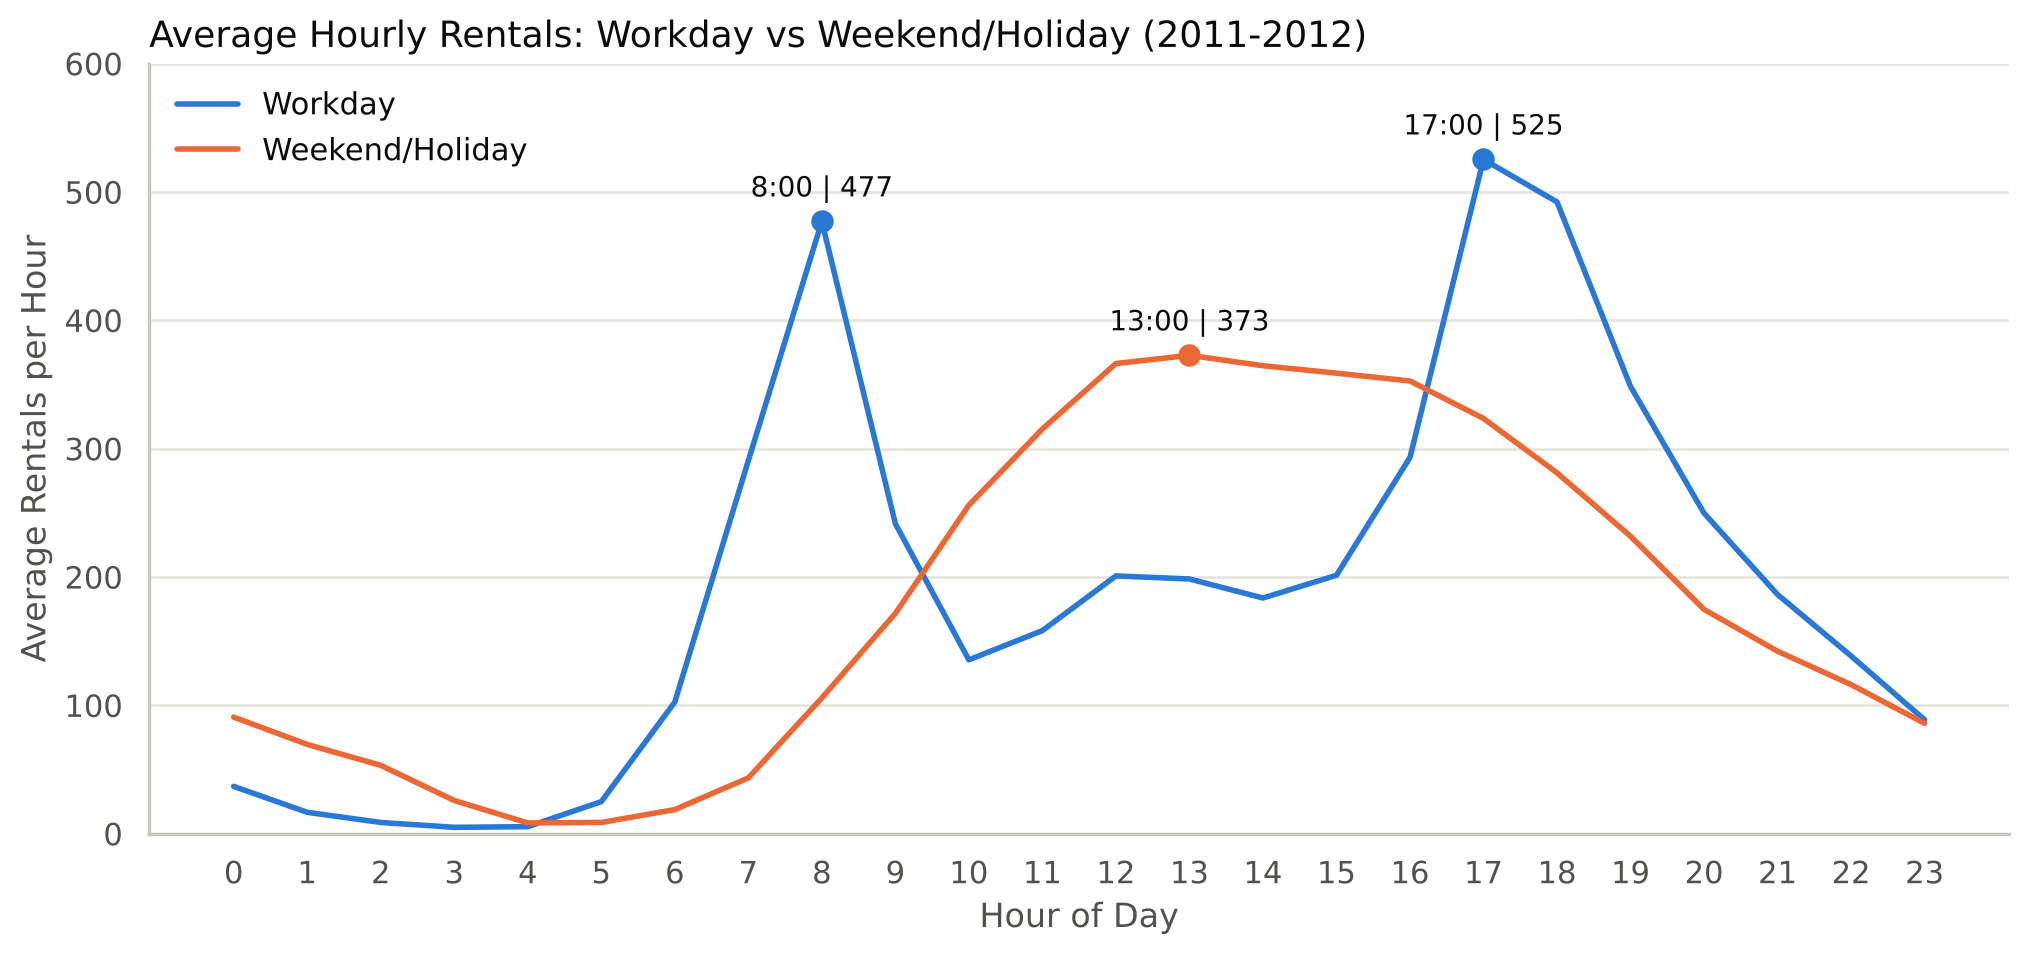

In [49]:
# Membuat line chart rata-rata sewa per jam pada hari kerja dan akhir pekan/libur

peak_hours = {'Workday': [8, 17], 'Weekend/Holiday': [13]}

fig, ax = plt.subplots(figsize=(12, 5))
for day_type, color in DAY_TYPE_COLORS.items():
    ax.plot(hourly_pattern.index, hourly_pattern[day_type], color=color, linewidth=2, label=day_type)
    for hour in peak_hours[day_type]:
        value = hourly_pattern.loc[hour, day_type]
        ax.scatter(hour, value, color=color, s=50, zorder=3)
        ax.annotate(f'{hour}:00 | {value:.0f}', (hour, value), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=10)

ax.set_xticks(range(24))
ax.set_ylim(0, 600)
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Average Rentals per Hour')
ax.set_title('Average Hourly Rentals: Workday vs Weekend/Holiday (2011-2012)', loc='left', fontsize=13)
ax.legend(loc='upper left', frameon=False)
sns.despine()
plt.show()

**Insight:**
- Hari kerja memiliki dua jam puncak yang terkait jam berangkat dan pulang kerja: pukul 17.00 dengan rata-rata 525 sewa per jam (tertinggi) dan pukul 08.00 dengan rata-rata 477 sewa per jam.
- Akhir pekan/libur hanya memiliki satu puncak pada pukul 13.00 dengan rata-rata 373 sewa per jam, dan permintaannya merata dari pukul 11.00 sampai 16.00.
- Puncak tertinggi di hari kerja sekitar 41% lebih tinggi daripada puncak akhir pekan/libur.

### Pertanyaan 2: Seberapa besar penurunan rata-rata penyewaan harian pada tiap musim dan kondisi cuaca dibandingkan kondisi terbaiknya (musim dengan rata-rata tertinggi dan cuaca cerah) sepanjang 2011-2012?

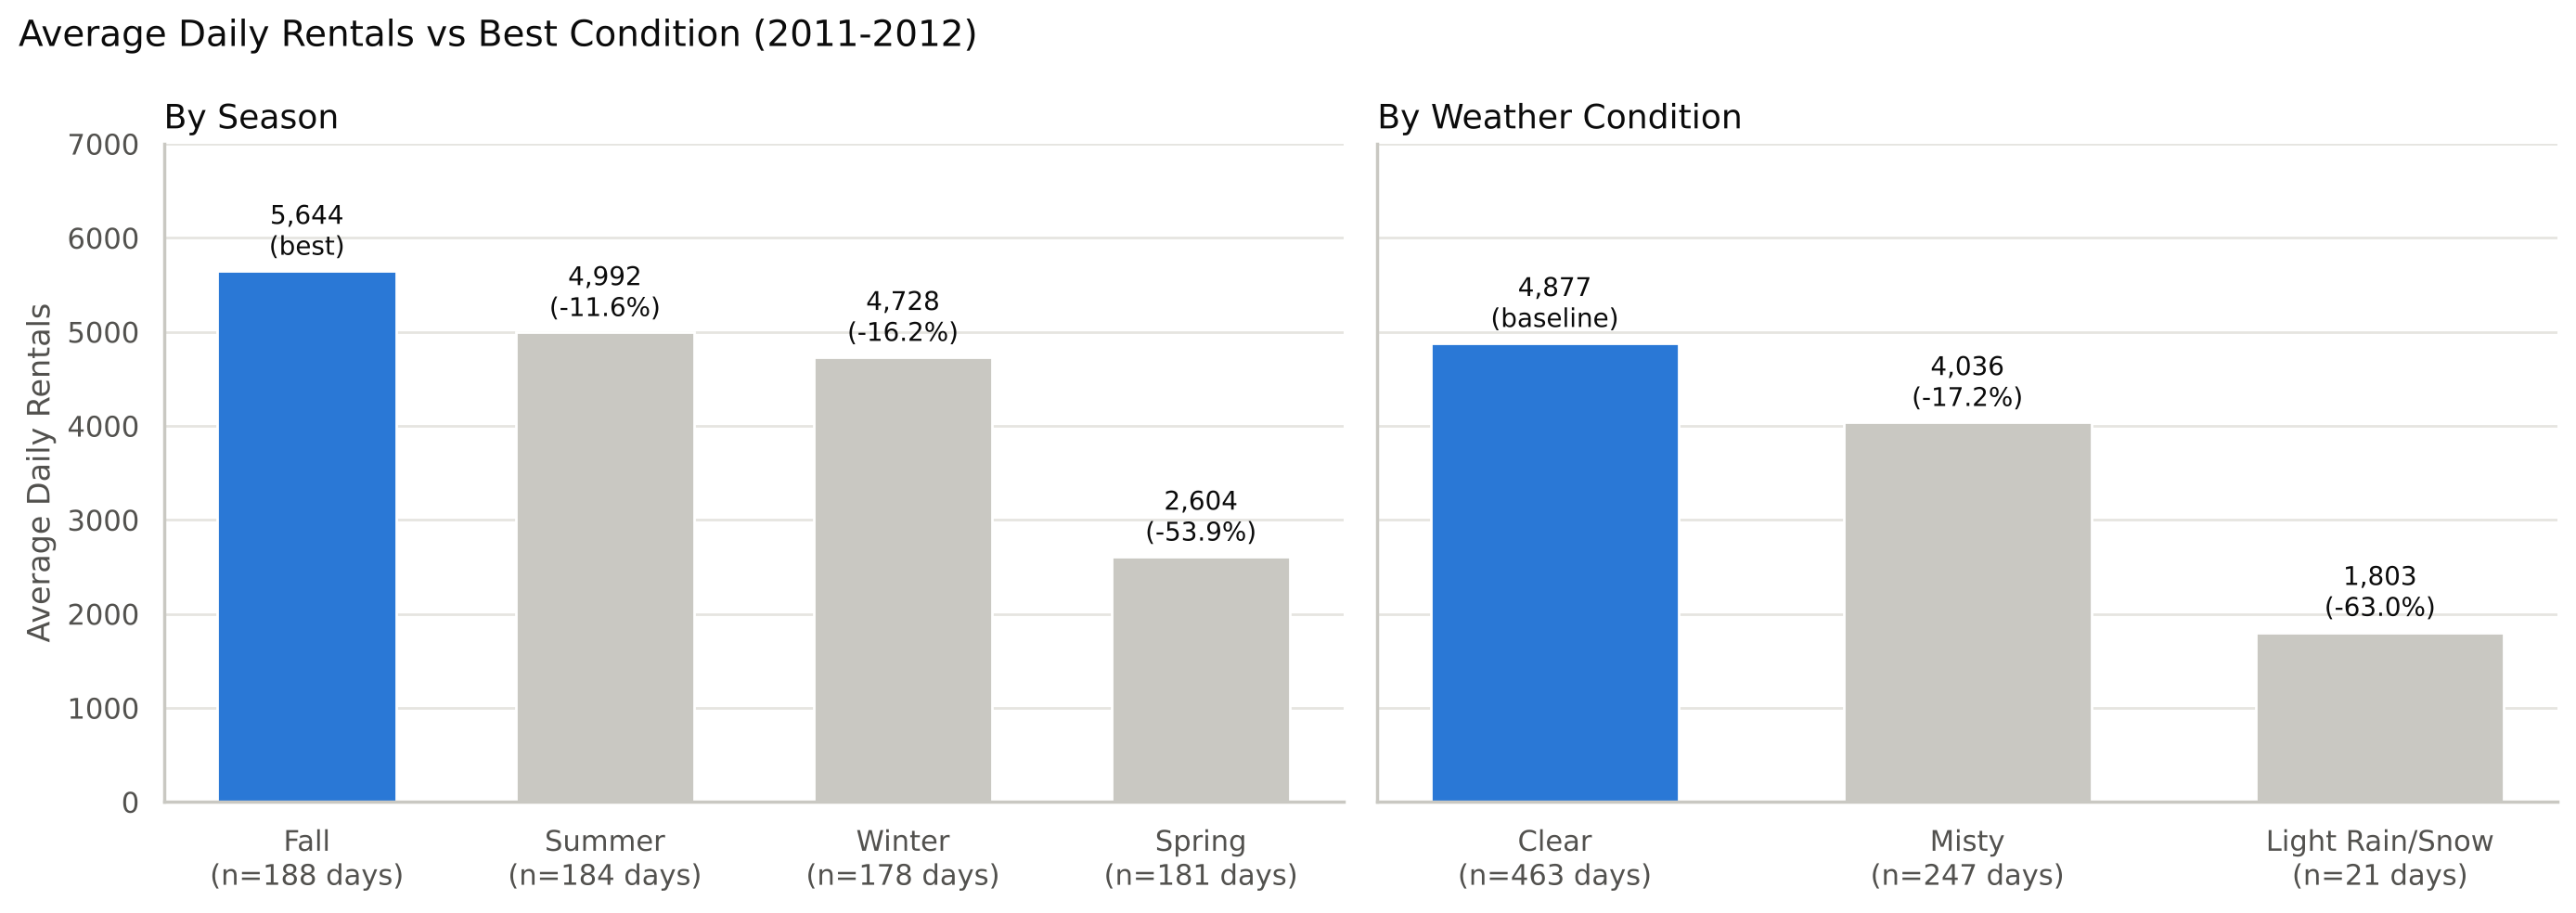

In [50]:
# Membuat bar chart rata-rata sewa harian per musim dan per kondisi cuaca beserta selisihnya terhadap kondisi terbaik

season_plot = season_stats.sort_values('avg_rentals', ascending=False)
weather_plot = weather_stats.sort_values('avg_rentals', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, data, gap_column, best_label, title in [
    (axes[0], season_plot, 'gap_vs_best_pct', 'best', 'By Season'),
    (axes[1], weather_plot, 'gap_vs_clear_pct', 'baseline', 'By Weather Condition')
]:
    colors = [COLOR_MAIN] + [COLOR_MUTED] * (len(data) - 1)
    bars = ax.bar(data.index, data['avg_rentals'], color=colors, width=0.6)
    labels = [f"{row.avg_rentals:,.0f}\n({best_label})" if i == 0 else f"{row.avg_rentals:,.0f}\n({getattr(row, gap_column):.1f}%)" for i, row in enumerate(data.itertuples())]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=10)
    ax.set_xticks(range(len(data)))
    ax.set_xticklabels([f"{name}\n(n={days} days)" for name, days in zip(data.index, data['days'])])
    ax.set_title(title, loc='left', fontsize=13)
    ax.set_xlabel('')

axes[0].set_ylabel('Average Daily Rentals')
axes[0].set_ylim(0, 7000)
sns.despine()
fig.suptitle('Average Daily Rentals vs Best Condition (2011-2012)', x=0.01, ha='left', fontsize=14)
plt.tight_layout()
plt.show()

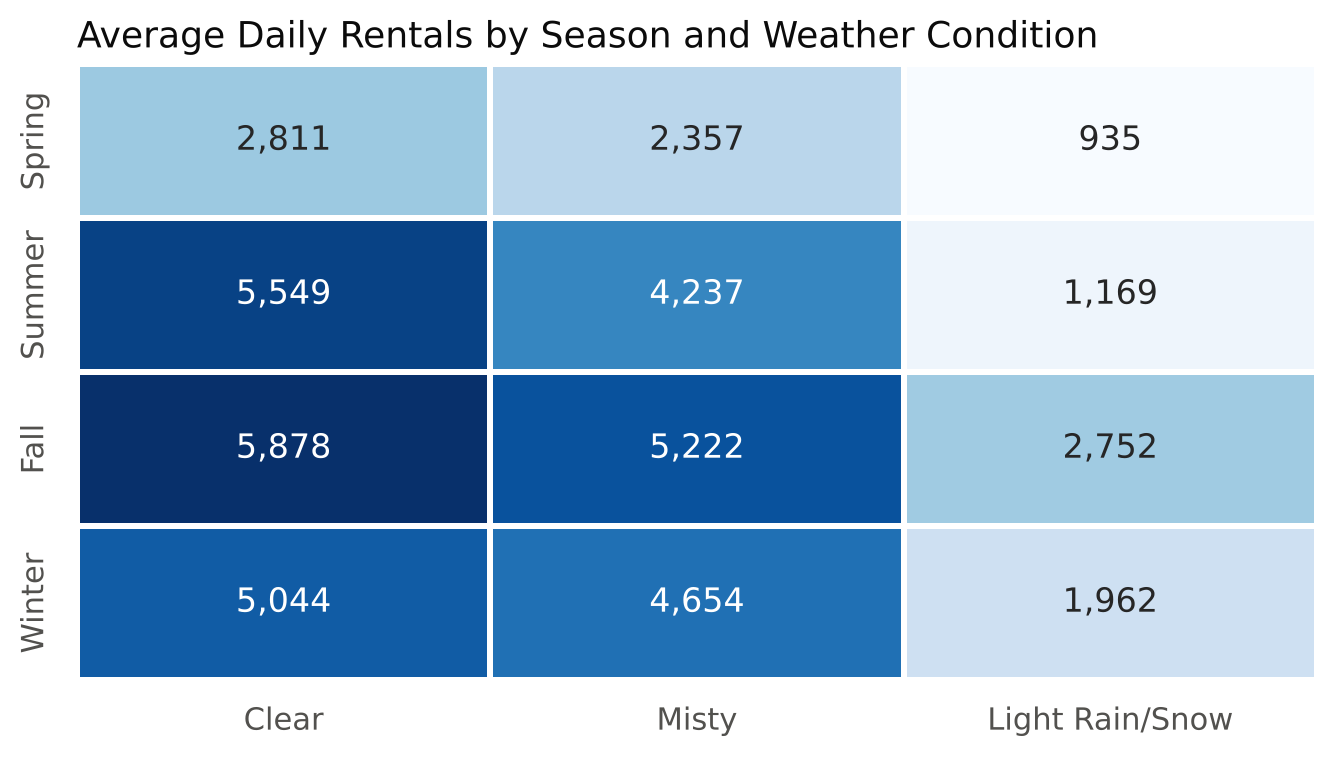

In [51]:
# Membuat heatmap rata-rata sewa harian pada kombinasi musim dan kondisi cuaca

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(season_weather_avg, annot=True, fmt=',.0f', cmap='Blues', linewidths=2, linecolor='white', cbar=False, ax=ax)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_title('Average Daily Rentals by Season and Weather Condition', loc='left', fontsize=13)
plt.show()

**Insight:**
- Musim Fall menjadi acuan terbaik dengan rata-rata 5.644 sewa per hari. Summer turun 11,6%, Winter turun 16,2%, dan Spring turun paling dalam yaitu 53,9% (2.604 sewa per hari).
- Dibandingkan cuaca Clear (4.877 sewa per hari), cuaca Misty turun 17,2% dan Light Rain/Snow turun 63,0% (1.803 sewa per hari, hanya dari 21 hari).
- Heatmap menunjukkan cuaca buruk menekan penyewaan di semua musim, tetapi musim tetap berpengaruh besar: Spring dengan cuaca Clear (2.811) masih lebih rendah daripada Fall dengan cuaca Misty (5.222).
- Kategori musim mengikuti pengkodean pada Readme dataset (1 = Spring sampai 4 = Winter), sehingga Spring dalam dataset ini mencakup bulan-bulan awal tahun yang paling sepi penyewaan.

### Pertanyaan 3: Berapa persen pertumbuhan total penyewaan pada setiap bulan di 2012 dibandingkan bulan yang sama di 2011, dan bulan apa yang pertumbuhannya paling tinggi dan paling rendah?

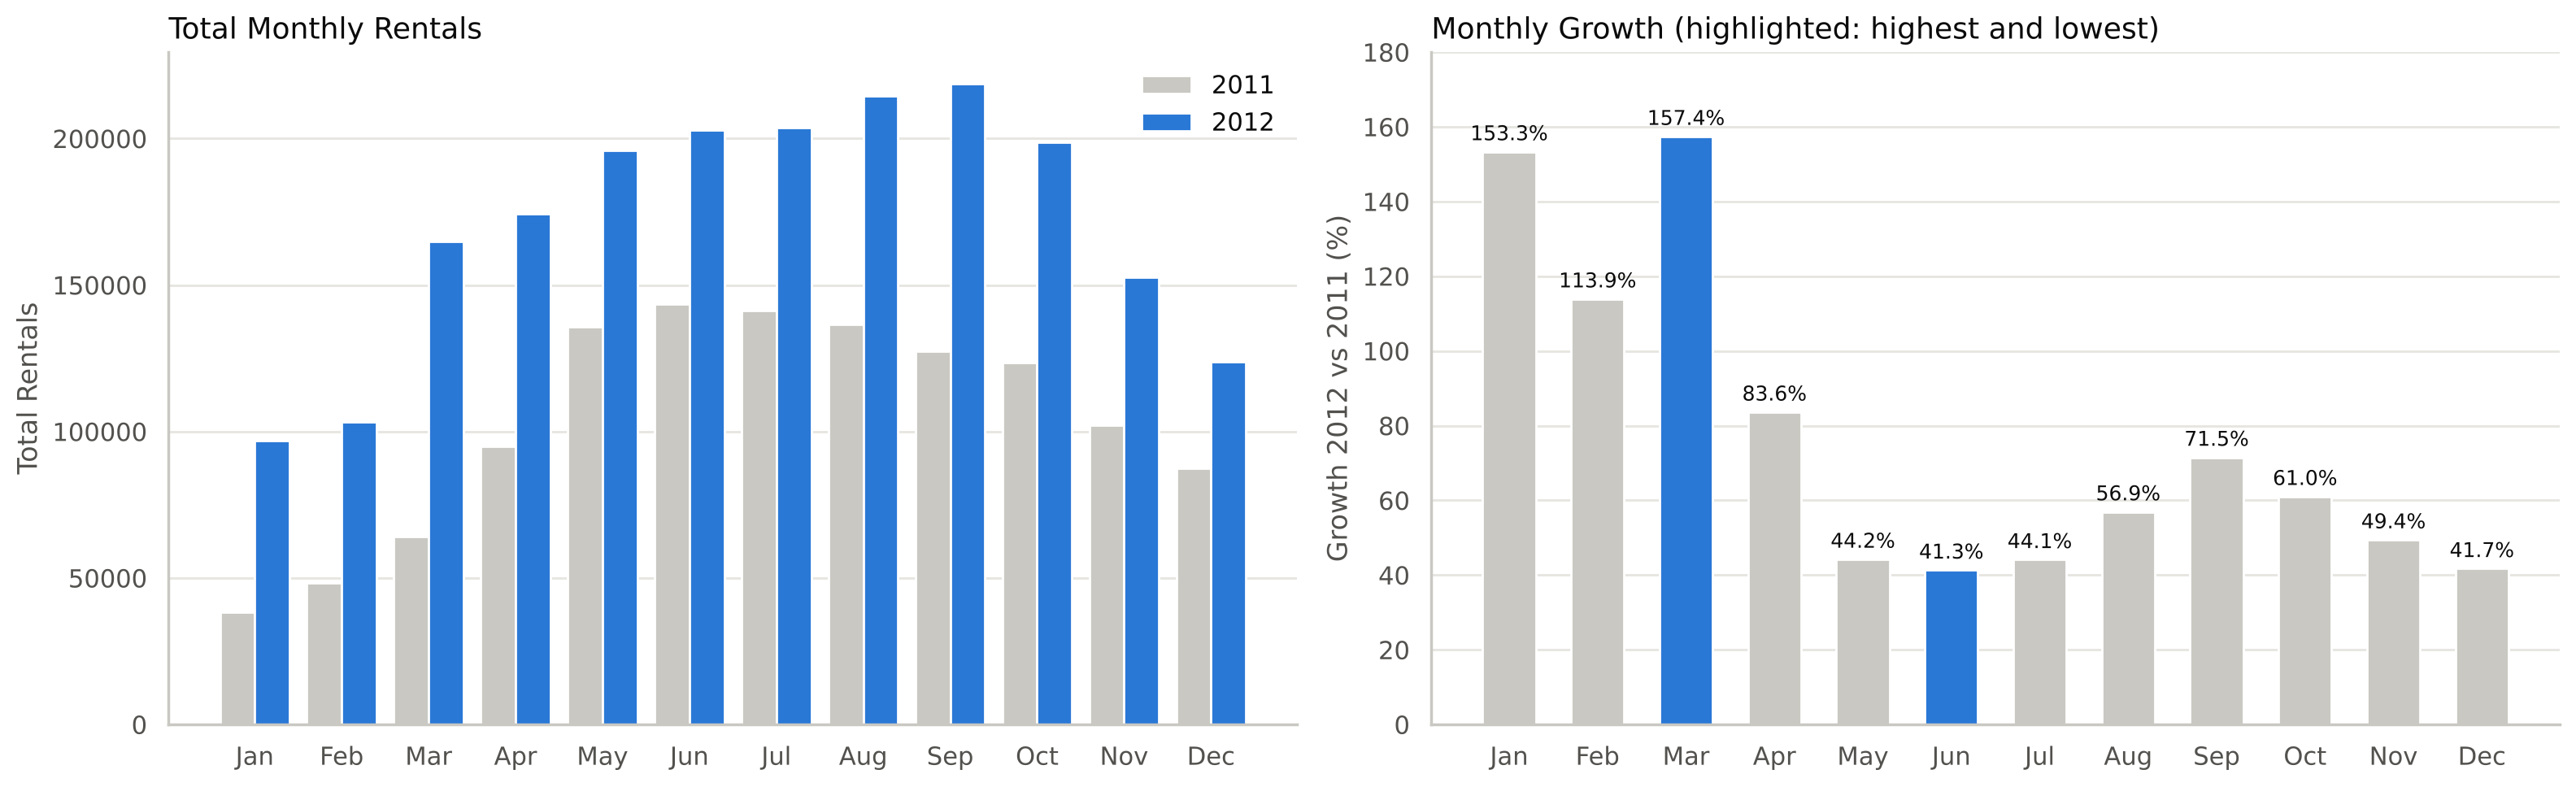

In [52]:
# Membuat grouped bar chart total sewa per bulan dan bar chart pertumbuhan 2012 terhadap 2011

x = np.arange(len(month_names))
width = 0.4
growth = monthly_rentals['growth_pct']
growth_colors = [COLOR_MAIN if value in (growth.max(), growth.min()) else COLOR_MUTED for value in growth]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].bar(x - width / 2, monthly_rentals[2011], width, color=COLOR_MUTED, label='2011')
axes[0].bar(x + width / 2, monthly_rentals[2012], width, color=COLOR_MAIN, label='2012')
axes[0].set_xticks(x)
axes[0].set_xticklabels(month_names)
axes[0].set_ylabel('Total Rentals')
axes[0].set_title('Total Monthly Rentals', loc='left', fontsize=13)
axes[0].legend(frameon=False)

bars = axes[1].bar(x, growth, color=growth_colors, width=0.6)
axes[1].bar_label(bars, labels=[f'{value:.1f}%' for value in growth], padding=3, fontsize=9)
axes[1].set_xticks(x)
axes[1].set_xticklabels(month_names)
axes[1].set_ylabel('Growth 2012 vs 2011 (%)')
axes[1].set_ylim(0, 180)
axes[1].set_title('Monthly Growth (highlighted: highest and lowest)', loc='left', fontsize=13)

sns.despine()
plt.tight_layout()
plt.show()

**Insight:**
- Semua bulan pada 2012 tumbuh dibandingkan bulan yang sama pada 2011, dengan rentang pertumbuhan 41,3% sampai 157,4%.
- Pertumbuhan tertinggi terjadi pada Maret (157,4%), disusul Januari (153,3%) dan Februari (113,9%). Pertumbuhan terendah terjadi pada Juni (41,3%), disusul Desember (41,7%) dan Mei (44,2%).
- Pertumbuhan paling tinggi terjadi pada bulan-bulan awal tahun karena basis penyewaan 2011 pada bulan tersebut masih rendah, sedangkan pada pertengahan tahun basis 2011 sudah tinggi sehingga persentasenya lebih kecil meskipun total sewanya paling besar (Jun-Sep 2012 di atas 200 ribu sewa per bulan).

### Pertanyaan 4: Berapa persen pengguna casual terhadap total penyewaan pada hari kerja dibandingkan hari libur/akhir pekan, dan pada tiap musim?

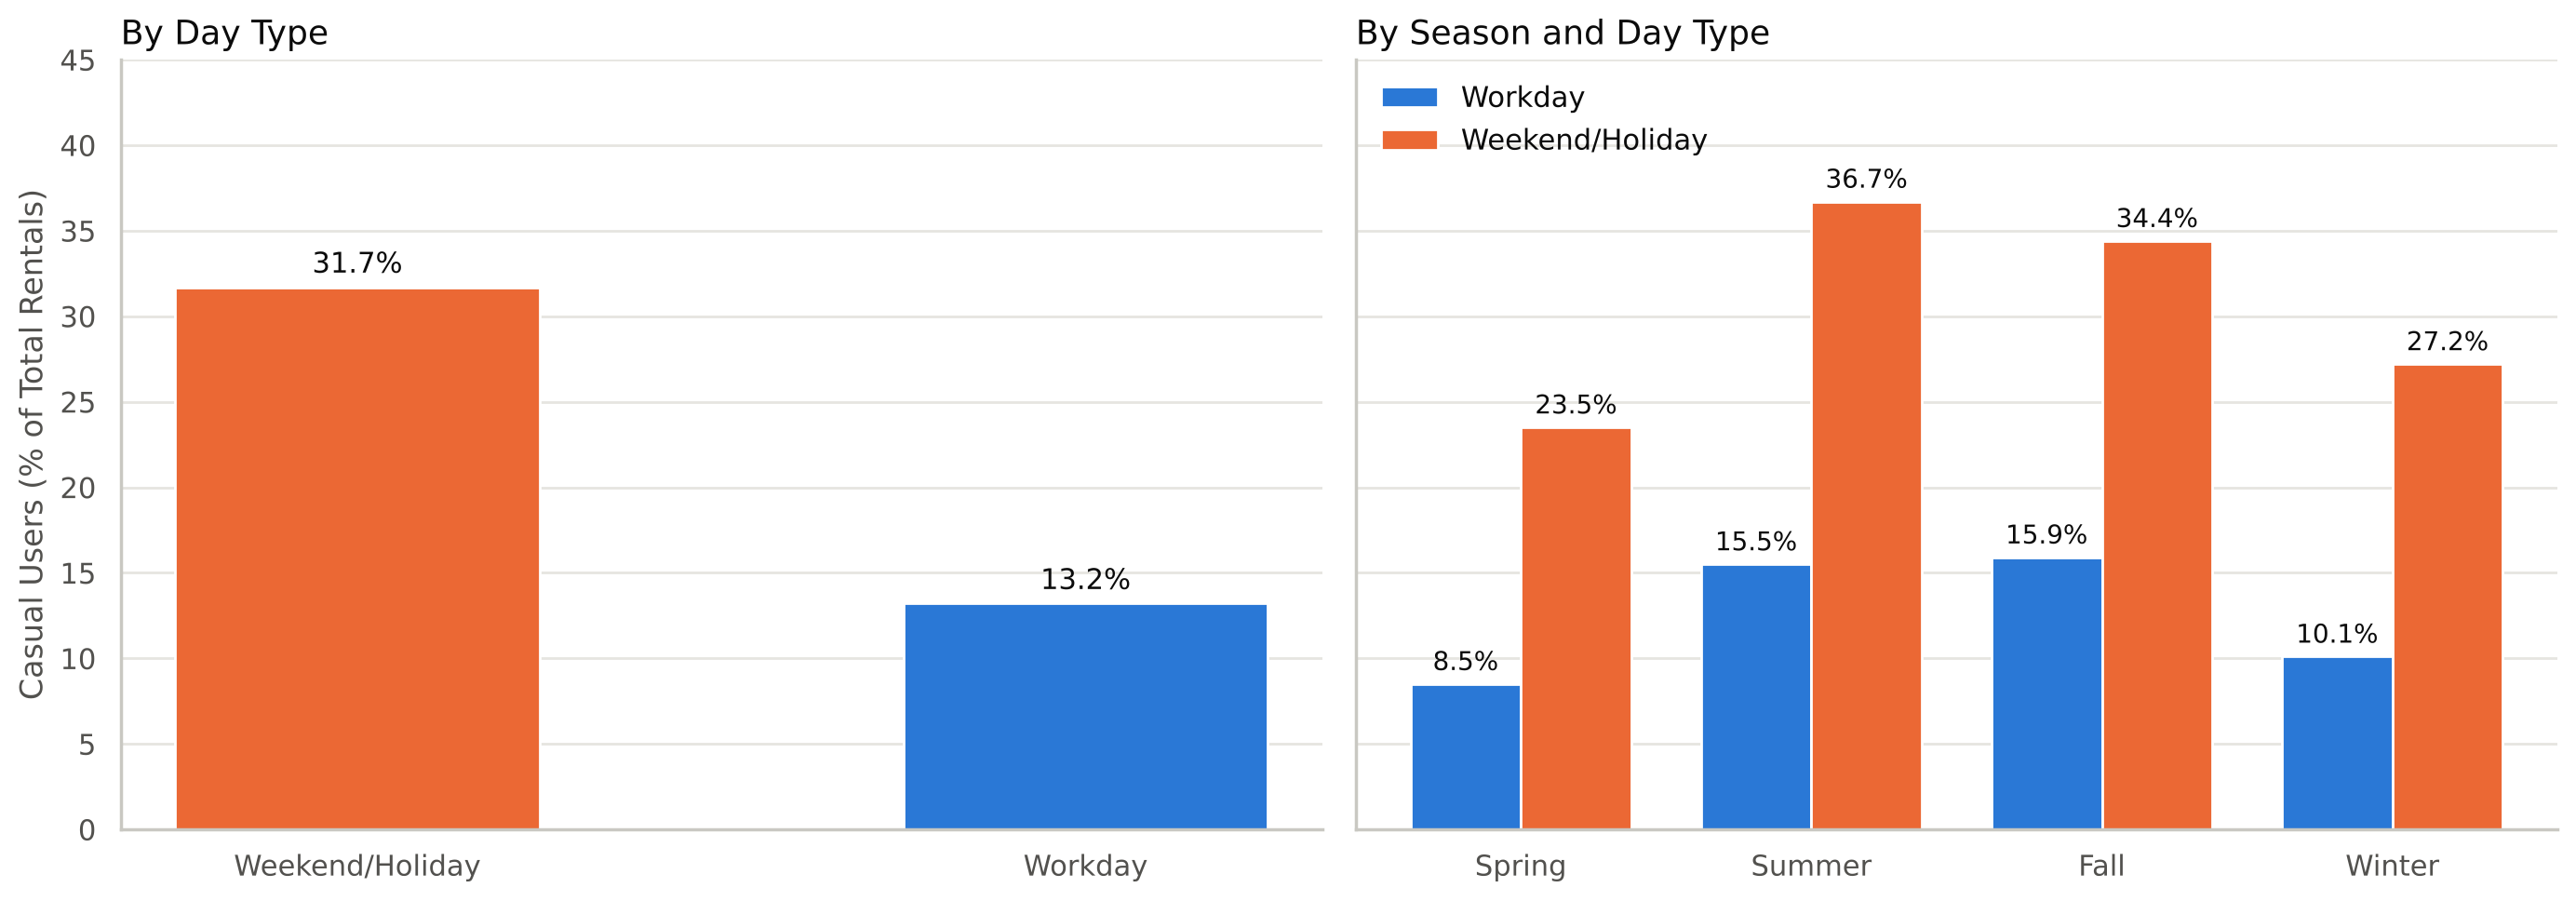

In [53]:
# Membuat bar chart persentase pengguna casual berdasarkan tipe hari dan musim

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

day_type_share = casual_share_day_type['casual_pct']
bars = axes[0].bar(day_type_share.index, day_type_share.values, color=[DAY_TYPE_COLORS[name] for name in day_type_share.index], width=0.5)
axes[0].bar_label(bars, labels=[f'{value:.1f}%' for value in day_type_share.values], padding=3, fontsize=11)
axes[0].set_ylabel('Casual Users (% of Total Rentals)')
axes[0].set_ylim(0, 45)
axes[0].set_title('By Day Type', loc='left', fontsize=13)

x = np.arange(len(season_order))
width = 0.38
for offset, day_type in zip([-width / 2, width / 2], ['Workday', 'Weekend/Holiday']):
    bars = axes[1].bar(x + offset, casual_share_combined[day_type], width, color=DAY_TYPE_COLORS[day_type], label=day_type)
    axes[1].bar_label(bars, labels=[f'{value:.1f}%' for value in casual_share_combined[day_type]], padding=3, fontsize=10)
axes[1].set_xticks(x)
axes[1].set_xticklabels(season_order)
axes[1].set_title('By Season and Day Type', loc='left', fontsize=13)
axes[1].legend(frameon=False, loc='upper left')

sns.despine()
plt.tight_layout()
plt.show()

**Insight:**
- Pengguna casual menyumbang 31,7% dari total sewa pada akhir pekan/libur, jauh lebih tinggi daripada hari kerja yang hanya 13,2%. Pada hari kerja, pengguna registered mendominasi dengan 86,8%.
- Porsi casual akhir pekan/libur lebih tinggi di semua musim, dengan nilai tertinggi pada Summer (36,7%) dan Fall (34,4%), dan terendah pada Spring (23,5%).
- Porsi casual pada hari kerja berkisar 8,5% (Spring) sampai 15,9% (Fall), jadi kesempatan konversi casual menjadi registered paling besar pada akhir pekan/libur di musim Summer dan Fall.

## Analisis Lanjutan (Opsional)

Teknik yang dipakai adalah **manual grouping (binning)**. Suhu harian (°C) dikelompokkan secara manual ke dalam empat kategori (Cold, Cool, Warm, Hot) agar pengaruh suhu terhadap penyewaan dapat dibandingkan antar kelompok, karena korelasi suhu dengan jumlah sewa sudah terlihat pada EDA (0,63). Hasilnya melengkapi Pertanyaan 2 untuk menentukan waktu promosi dan perawatan armada.

In [54]:
# Mengelompokkan suhu harian ke dalam empat kategori secara manual lalu menghitung rata-rata sewa harian tiap kategori

temperature_bins = [0, 10, 20, 30, 40]
temperature_labels = ['Cold (<10°C)', 'Cool (10-20°C)', 'Warm (20-30°C)', 'Hot (30°C+)']
day_df['temperature_group'] = pd.cut(day_df['temperature'], bins=temperature_bins, labels=temperature_labels, right=False)

temperature_stats = day_df.groupby('temperature_group', observed=True).agg(
    avg_rentals=('count', 'mean'),
    days=('count', 'count')
).round(0)
temperature_stats

,avg_rentals,days
temperature_group,,
Cold (<10°C),1678.0,60
Cool (10-20°C),3692.0,299
Warm (20-30°C),5656.0,297
Hot (30°C+),5441.0,75


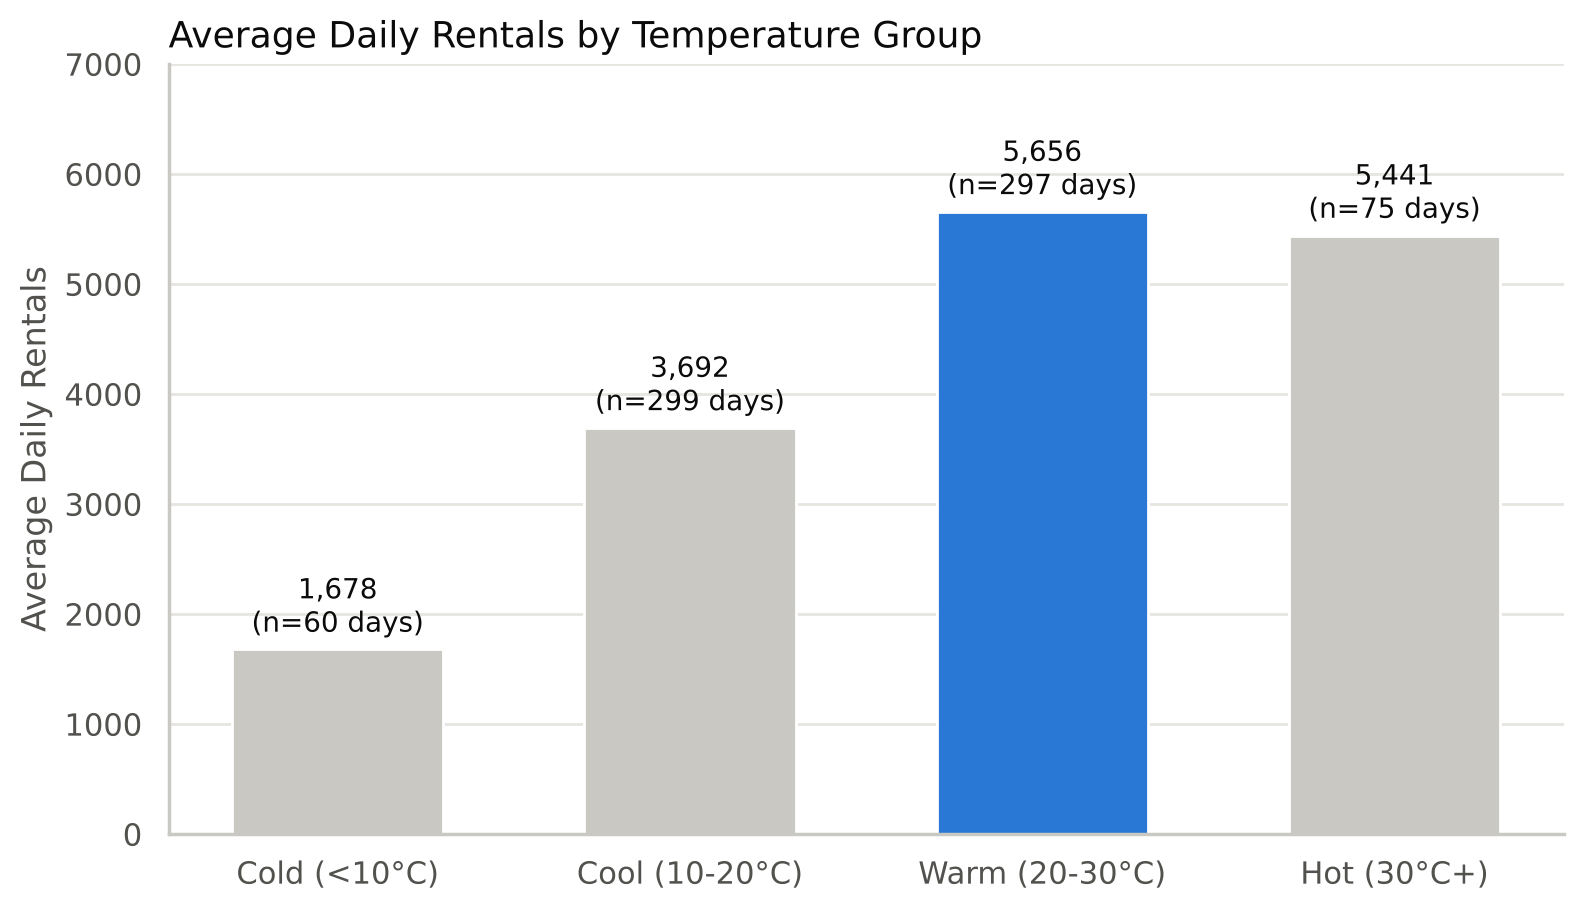

In [55]:
# Membuat bar chart rata-rata sewa harian berdasarkan kelompok suhu

colors = [COLOR_MAIN if value == temperature_stats['avg_rentals'].max() else COLOR_MUTED for value in temperature_stats['avg_rentals']]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(temperature_stats.index.astype(str), temperature_stats['avg_rentals'], color=colors, width=0.6)
ax.bar_label(bars, labels=[f"{row.avg_rentals:,.0f}\n(n={row.days} days)" for row in temperature_stats.itertuples()], padding=3, fontsize=10)
ax.set_ylim(0, 7000)
ax.set_xlabel('')
ax.set_ylabel('Average Daily Rentals')
ax.set_title('Average Daily Rentals by Temperature Group', loc='left', fontsize=13)
sns.despine()
plt.show()

**Insight:**
- Rata-rata sewa harian naik tajam dari kelompok Cold (1.678) ke Cool (3.692) dan Warm (5.656).
- Kelompok Hot (30°C+) sedikit lebih rendah (5.441) daripada Warm (5.656), sehingga permintaan tertinggi terjadi pada suhu 20-30°C dan mulai turun saat suhu terlalu panas. Kelompok ini hanya berasal dari 75 hari.
- Hari dengan suhu di bawah 10°C hanya 60 hari, tetapi penyewaannya kurang dari sepertiga hari bersuhu 20-30°C.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Penyewaan pada hari kerja memuncak pada pukul 17.00 (rata-rata 525 sewa per jam) dengan puncak kedua pukul 08.00 (477), sedangkan pada akhir pekan/libur hanya ada satu puncak pada pukul 13.00 (373) dengan permintaan tinggi dari pukul 11.00 sampai 16.00.
- **Conclusion pertanyaan 2:** Dibandingkan musim terbaik (Fall, 5.644 sewa per hari), rata-rata sewa turun 11,6% pada Summer, 16,2% pada Winter, dan 53,9% pada Spring. Dibandingkan cuaca Clear (4.877), cuaca Misty turun 17,2% dan Light Rain/Snow turun 63,0%. Suhu 20-30°C menghasilkan penyewaan tertinggi.
- **Conclusion pertanyaan 3:** Penyewaan 2012 lebih tinggi daripada 2011 pada semua bulan. Pertumbuhan tertinggi terjadi pada Maret (157,4%) dan terendah pada Juni (41,3%), dengan pertumbuhan terbesar terjadi pada bulan awal tahun yang basis 2011-nya rendah.
- **Conclusion pertanyaan 4:** Pengguna casual menyumbang 31,7% sewa pada akhir pekan/libur dan 13,2% pada hari kerja. Porsi casual tertinggi ada di musim Summer (22,2%) dan Fall (21,3%), dan terendah di Spring (12,9%).

**Rekomendasi Action Item:**
- Redistribusi sepeda pada hari kerja sebaiknya dijadwalkan sebelum pukul 08.00 dan sebelum pukul 17.00 (misalnya sepeda dipindahkan ke stasiun dekat kawasan kantor/transit), sedangkan pada akhir pekan/libur fokuskan stok pada stasiun wisata/taman menjelang pukul 11.00.
- Jadwalkan perawatan armada pada musim Spring dan saat cuaca buruk ketika permintaan paling rendah, dan pastikan armada penuh pada musim Fall dan Summer.
- Gunakan bulan dengan basis rendah (Januari sampai Maret) untuk menyusun target pertumbuhan yang lebih agresif, dan gunakan Juni sampai September sebagai acuan kapasitas armada karena total sewa bulanan tertinggi.
- Arahkan promosi konversi casual menjadi anggota registered pada akhir pekan/libur di musim Summer dan Fall, misalnya melalui penawaran keanggotaan atau diskon pada pukul 11.00 sampai 16.00.